# DS02 ? XGBoost Deneme 2

VS Code'da Colab ?al??ma zaman?n? se?ip h?creleri s?rayla ?al??t?r?n. ?lk kod
h?cresi Drive'daki DS02 HDF5 dosyas?ndan eksik pencere metadata?s?n? ?retir.
Sonraki ?al??t?rmalarda haz?r CSV kullan?l?r. Kar??la?t?rma DS02 `dev`
motorlar?yla yap?l?r.

In [5]:
from pathlib import Path

import h5py
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from google.colab import drive
from IPython.display import display
from xgboost import XGBRegressor

drive.mount("/content/drive")

drive_root = Path("/content/drive/MyDrive/ncmapss")
h5_path = drive_root / "N-CMAPSS_DS02-006.h5"
metadata_path = drive_root / "ds02_w256_s256" / "window_metadata.csv"
output_dir = drive_root / "deneyler" / "xgboost_v02_pencere256"

def read_names(dataset):
    return [
        value.decode("utf-8").rstrip("\x00") if isinstance(value, bytes) else str(value)
        for value in np.asarray(dataset[()]).reshape(-1)
    ]


WINDOW_SIZE = 256
STRIDE = 256
FLIGHT_KEYS = ["unit", "cycle"]
META_COLUMNS = ["window_id", *FLIGHT_KEYS, "rul", "start_row", "end_row"]

if not h5_path.is_file():
    raise FileNotFoundError(h5_path)


def read_dev_flights(path):
    with h5py.File(path, "r") as h5:
        id_names = read_names(h5["A_var"])
        if id_names[:2] != FLIGHT_KEYS:
            raise ValueError("DS02 A_dev s?tun s?ras? beklenen unit, cycle ile ba?lam?yor.")
        identifiers = h5["A_dev"][:, :2].astype(np.int32)
        starts = np.r_[0, np.flatnonzero(np.any(identifiers[1:] != identifiers[:-1], axis=1)) + 1]
        ends = np.r_[starts[1:], len(identifiers)]
        targets = h5["Y_dev"][starts, 0]

    flights = pd.DataFrame(identifiers[starts], columns=FLIGHT_KEYS)
    return flights.assign(start_row=starts, end_row=ends, rul=targets.astype(float))


def build_window_metadata(flights):
    records = []
    for flight in flights.itertuples(index=False):
        for start in range(flight.start_row, flight.end_row - WINDOW_SIZE + 1, STRIDE):
            records.append((len(records), flight.unit, flight.cycle, flight.rul, start, start + WINDOW_SIZE))
    return pd.DataFrame(records, columns=META_COLUMNS)


def validate_generated_metadata(windows, flights):
    if len(flights) != 446 or flights.duplicated(FLIGHT_KEYS).any():
        raise ValueError("HDF5 i?inde 446 benzersiz dev u?u?u bekleniyor.")
    if len(windows) != 20_339 or not windows["window_id"].is_unique:
        raise ValueError("20.339 benzersiz pencere bekleniyor.")

    groups = {key: group for key, group in windows.groupby(FLIGHT_KEYS, sort=False)}
    for flight in flights.itertuples(index=False):
        group = groups.pop((flight.unit, flight.cycle))
        count = (flight.end_row - flight.start_row) // WINDOW_SIZE
        starts = flight.start_row + np.arange(count) * STRIDE
        ends = group["end_row"].to_numpy()
        np.testing.assert_array_equal(group["start_row"], starts)
        np.testing.assert_array_equal(ends, starts + WINDOW_SIZE)
        if np.any(ends > flight.end_row):
            raise ValueError(f"Pencere u?u? s?n?r?n? a??yor: {flight.unit}, {flight.cycle}")
    if groups:
        raise ValueError("Metadata i?inde HDF5 ile e?le?meyen u?u? var.")


def load_window_metadata(path, flights):
    if path.is_file():
        print(f"Haz?r metadata kullan?l?yor: {path}")
        return pd.read_csv(path, dtype={column: "int64" for column in META_COLUMNS if column != "rul"})

    windows = build_window_metadata(flights)
    validate_generated_metadata(windows, flights)
    path.parent.mkdir(parents=True, exist_ok=True)
    windows.to_csv(path, index=False, lineterminator="\r\n")
    print(f"{len(flights)} u?u? ve {len(windows):,} benzersiz pencere do?ruland?. Metadata kaydedildi: {path}")
    return windows


dev_flights = read_dev_flights(h5_path)
metadata = load_window_metadata(metadata_path, dev_flights)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
446 u?u? ve 20,339 benzersiz pencere do?ruland?. Metadata kaydedildi: /content/drive/MyDrive/ncmapss/ds02_w256_s256/window_metadata.csv


## Pencere ve u?u? girdileri

Metadata'daki `start_row` s?f?r tabanl? ve dahil, `end_row` hari?tir.
Her u?u?ta `W_dev` ve `X_s_dev` birer blok olarak okunur. V02 her pencerenin
ortalama ve pop?lasyon standart sapmas?n? kullan?r. V01 t?m u?u?un ortalama
ve standart sapmas?n?, ayr?ca motorun o u?u?a kadarki u?u? ortalamalar?n?n
birikimli ortalamas?n? kullan?r.

In [6]:
assert list(metadata.columns) == META_COLUMNS
assert len(metadata) == 20_339 and metadata["window_id"].is_unique
metadata = metadata.sort_values("window_id", ignore_index=True)


def extract_features(path, windows, flights):
    window_groups = {key: group for key, group in windows.groupby(FLIGHT_KEYS, sort=False)}
    v02_blocks = []
    v01_rows = []
    with h5py.File(path, "r") as h5:
        groups = [(h5[f"{key}_dev"], [f"{key}_{name}" for name in read_names(h5[f"{key}_var"])])
                  for key in ("W", "X_s")]
        feature_columns = [
            f"{name}_{stat}"
            for _, names in groups
            for stat in ("mean", "std")
            for name in names
        ]
        mean_columns = [f"{name}_mean" for _, names in groups for name in names]
        assert [len(names) for _, names in groups] == [4, 14]
        assert len(set(feature_columns)) == 36

        for unit, cycle, start, end, rul in flights.itertuples(index=False, name=None):
            flight_windows = window_groups.pop((unit, cycle)).sort_values("start_row")
            expected_starts = np.arange(start, end - WINDOW_SIZE + 1, WINDOW_SIZE)
            np.testing.assert_array_equal(flight_windows["start_row"], expected_starts)
            np.testing.assert_array_equal(flight_windows["end_row"], expected_starts + WINDOW_SIZE)
            np.testing.assert_allclose(flight_windows["rul"], rul, rtol=0, atol=0)

            flight_features = []
            window_features = []
            for dataset, names in groups:
                raw = dataset[start:end]
                window_rows = raw[:len(expected_starts) * WINDOW_SIZE].reshape(
                    len(expected_starts), WINDOW_SIZE, len(names)
                )
                flight_features.extend(np.mean(raw, axis=0, dtype=np.float64))
                flight_features.extend(np.std(raw, axis=0, dtype=np.float64, ddof=0))
                window_features.extend([
                    np.mean(window_rows, axis=1, dtype=np.float64),
                    np.std(window_rows, axis=1, dtype=np.float64, ddof=0),
                ])

            v01_rows.append((unit, cycle, rul, *flight_features))
            stats = pd.DataFrame(np.hstack(window_features), index=flight_windows.index, columns=feature_columns)
            v02_blocks.append(flight_windows.join(stats))

    assert not window_groups
    v02 = pd.concat(v02_blocks).sort_index().rename(columns={"rul": "RUL"})
    v01 = pd.DataFrame(v01_rows, columns=[*FLIGHT_KEYS, "RUL", *feature_columns])
    v01 = v01.sort_values(FLIGHT_KEYS, ignore_index=True)
    assert not v01.duplicated(FLIGHT_KEYS).any()
    history = (
        v01.groupby("unit", sort=False)[mean_columns]
        .expanding().mean().droplevel("unit").add_suffix("_to_date")
    )
    return v01.join(history), v02, feature_columns


v01, v02, v02_features = extract_features(h5_path, metadata, dev_flights)
v01_features = v01.columns.drop([*FLIGHT_KEYS, "RUL"]).tolist()
units = sorted(v01["unit"].unique())

assert len(units) == 6 and set(v02["unit"]) == set(units)
assert v01[v01_features].shape == (446, 54)
assert v02[v02_features].shape == (20_339, 36)
print(f"V01: {v01[v01_features].shape} | V02: {v02[v02_features].shape}")
with pd.option_context("display.max_columns", None):
    display(v02.loc[:, ["window_id", *v02_features, "RUL"]].head(2))

V01: (446, 54) | V02: (20339, 36)


,window_id,W_alt_mean,W_Mach_mean,W_TRA_mean,W_T2_mean,W_alt_std,W_Mach_std,W_TRA_std,W_T2_std,X_s_T24_mean,X_s_T30_mean,X_s_T48_mean,X_s_T50_mean,X_s_P15_mean,X_s_P2_mean,X_s_P21_mean,X_s_P24_mean,X_s_Ps30_mean,X_s_P40_mean,X_s_P50_mean,X_s_Nf_mean,X_s_Nc_mean,X_s_Wf_mean,X_s_T24_std,X_s_T30_std,X_s_T48_std,X_s_T50_std,X_s_P15_std,X_s_P2_std,X_s_P21_std,X_s_P24_std,X_s_Ps30_std,X_s_P40_std,X_s_P50_std,X_s_Nf_std,X_s_Nc_std,X_s_Wf_std,RUL
0,0,10619.550781,0.477126,77.315735,502.723648,334.217377,0.020011,0.210968,0.642364,600.773602,1438.587419,1817.373244,1224.741293,15.713847,11.509168,15.953144,20.041818,328.911873,334.223340,12.408352,2165.346245,8591.742194,3.824599,0.878203,0.971522,0.984106,1.792969,0.034048,0.024210,0.034567,0.045073,0.985118,0.993169,0.111607,3.227401,3.128973,0.013537,74.0
1,1,12631.082031,0.518039,78.578122,499.046029,718.349577,0.004030,0.342884,2.347599,597.367375,1430.622924,1807.247118,1212.023341,14.948807,10.928016,15.176454,19.130343,313.594277,318.657671,11.604044,2168.898385,8566.581710,3.633263,2.542541,5.139957,6.264073,5.385688,0.375692,0.284181,0.381413,0.469554,7.363518,7.488054,0.309019,2.285924,16.320381,0.092626,74.0


## Motor bazl? e?itim

Her d?? katta bir motor ayr?l?r. Kalan be? motor, i? do?rulamada s?rayla ayr?l?r.
?? do?rulamada u?u? ba??na e?it a??rl?kl? RMSE ile erken durdurma uygulan?r.
Be? i? katta se?ilen a?a? say?lar?n?n medyan?yla d?? e?itim motorlar?nda model
yeniden e?itilir. Her e?itim k?mesinde a??rl?klar?n ortalamas? 1'dir.

In [7]:
model_params = dict(
    objective="reg:squarederror",
    eval_metric="rmse",
    tree_method="hist",
    learning_rate=0.03,
    max_depth=3,
    random_state=42,
)

def flight_weights(frame):
    counts = frame.groupby(FLIGHT_KEYS)["RUL"].transform("size")
    weights = 1.0 / counts.to_numpy()
    return weights / weights.mean()


def select_rounds(training, columns):
    best_rounds = []
    for unit in sorted(training["unit"].unique()):
        inner_train = training.loc[training["unit"] != unit]
        inner_valid = training.loc[training["unit"] == unit]
        model = XGBRegressor(**model_params, n_estimators=1000, early_stopping_rounds=50)
        model.fit(
            inner_train[columns], inner_train["RUL"],
            sample_weight=flight_weights(inner_train),
            eval_set=[(inner_valid[columns], inner_valid["RUL"])],
            sample_weight_eval_set=[flight_weights(inner_valid)],
            verbose=False,
        )
        best_rounds.append(model.best_iteration + 1)
    return int(np.median(best_rounds))


def predict_outer_folds(frame, columns, version):
    predictions = []
    for unit in units:
        training = frame.loc[frame["unit"] != unit]
        held_out = frame.loc[frame["unit"] == unit]
        rounds = select_rounds(training, columns)
        model = XGBRegressor(**model_params, n_estimators=rounds)
        model.fit(training[columns], training["RUL"], sample_weight=flight_weights(training))

        ids = ["window_id"] if "window_id" in frame.columns else []
        result = held_out[[*ids, *FLIGHT_KEYS, "RUL"]].copy()
        result[version] = model.predict(held_out[columns])
        predictions.append(result)
        print(f"{version} | Motor {unit} | {rounds} a?a?")
    return pd.concat(predictions).sort_index()


v01_oof = predict_outer_folds(v01, v01_features, "V01")
v02_oof = predict_outer_folds(v02, v02_features, "V02")
assert len(v02_oof) == len(v02) and v02_oof["window_id"].is_unique

V01 | Motor 2 | 70 a?a?
V01 | Motor 5 | 101 a?a?
V01 | Motor 10 | 116 a?a?
V01 | Motor 16 | 231 a?a?
V01 | Motor 18 | 55 a?a?
V01 | Motor 20 | 213 a?a?
V02 | Motor 2 | 1000 a?a?
V02 | Motor 5 | 1000 a?a?
V02 | Motor 10 | 1000 a?a?
V02 | Motor 16 | 1000 a?a?
V02 | Motor 18 | 1000 a?a?
V02 | Motor 20 | 1000 a?a?


## U?u? bazl? sonu?lar

V02'de her u?u? i?in pencere tahminlerinin medyan? al?n?r. MAE ve RMSE her
u?u?a e?it a??rl?k verir ve yaln?zca d?? kat tahminlerinden hesaplan?r.

In [8]:
v02_flights = v02_oof.groupby(FLIGHT_KEYS, as_index=False).agg(
    RUL=("RUL", "first"), V02=("V02", "median")
)
flight_predictions = v01_oof.merge(
    v02_flights, on=FLIGHT_KEYS, validate="one_to_one", suffixes=("", "_v02")
).sort_values(FLIGHT_KEYS, ignore_index=True)
assert len(flight_predictions) == len(v01_oof) == len(v02_flights) == 446
np.testing.assert_array_equal(flight_predictions["RUL"], flight_predictions["RUL_v02"])
flight_predictions = flight_predictions.drop(columns="RUL_v02")

metric_rows = []
for label, flights in [*flight_predictions.groupby("unit"), ("T?m?", flight_predictions)]:
    for version in ("V01", "V02"):
        errors = flights[version] - flights["RUL"]
        metric_rows.append({
            "motor": label, "model": version, "ucus_sayisi": len(flights),
            "MAE": errors.abs().mean(), "RMSE": np.sqrt(errors.pow(2).mean()),
        })
metrics = pd.DataFrame(metric_rows)
display(metrics.round(3))

,motor,model,ucus_sayisi,MAE,RMSE
0,2,V01,75,6.250,8.408
1,2,V02,75,9.470,10.961
2,5,V01,89,10.636,14.747
3,5,V02,89,11.719,16.539
4,10,V01,82,8.778,11.751
5,10,V02,82,9.819,12.819
6,16,V01,63,7.728,10.303
7,16,V02,63,9.168,10.160
8,18,V01,71,11.100,13.613
9,18,V02,71,7.871,9.137


## Motor grafikleri

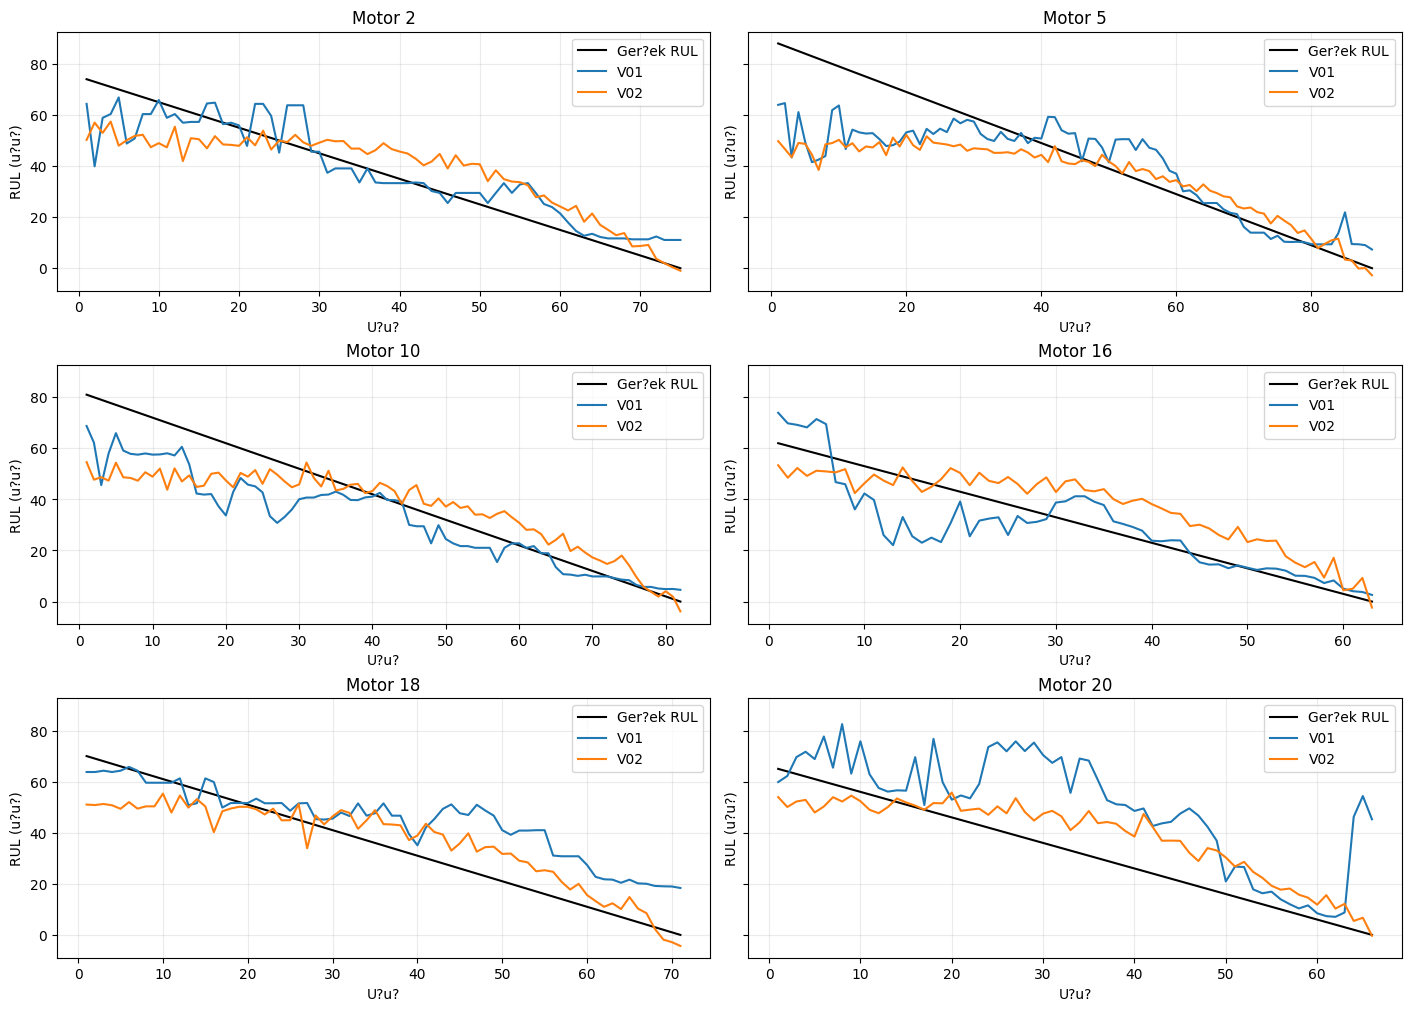

In [9]:
fig, axes = plt.subplots(3, 2, figsize=(14, 10), sharey=True, layout="constrained")
for ax, (unit, flights) in zip(axes.flat, flight_predictions.groupby("unit")):
    ax.plot(flights["cycle"], flights["RUL"], label="Ger?ek RUL", color="black")
    ax.plot(flights["cycle"], flights["V01"], label="V01")
    ax.plot(flights["cycle"], flights["V02"], label="V02")
    ax.set(title=f"Motor {unit}", xlabel="U?u?", ylabel="RUL (u?u?)")
    ax.grid(alpha=0.25)
    ax.legend()
plt.show()

## Drive kayd?

In [10]:
output_dir.mkdir(parents=True, exist_ok=True)
v02.to_parquet(output_dir / "v02_ozellikler.parquet", index=False, engine="pyarrow")
flight_predictions.to_csv(output_dir / "ucus_tahminleri.csv", index=False)
metrics.to_csv(output_dir / "karsilastirma_metrikleri.csv", index=False)
print(output_dir)

/content/drive/MyDrive/ncmapss/deneyler/xgboost_v02_pencere256
